# HW1 — Classical Image Processing (Colab starter)
智慧醫療影像與訊號處理 · W3

依題目卷 Part B / Part C 填完 TODO。**Runtime → Run all** 要能無錯執行。
影像用 scikit-image 內建醫學影像（`data.brain()` 腦 MRI / `shepp_logan_phantom()` CT phantom），不必上傳檔案。


In [ ]:
# === Setup: run me first ===
# scikit-image is preinstalled on Colab; uncomment if you hit a version issue:
# !pip install -U scikit-image
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, exposure, filters, feature, morphology, util, measure, color
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
import pandas as pd

def load_image():
    """Return one medical image slice as float in [0, 1]."""
    try:
        vol = data.brain()                      # brain MRI (downloads on first call)
        im = vol[vol.shape[0] // 2].astype(float)
        return im / im.max()
    except Exception:
        return util.img_as_float(data.shepp_logan_phantom())

img = load_image()
print("loaded:", img.shape, img.dtype, round(float(img.min()), 3), round(float(img.max()), 3))


loaded: (256, 256) float64 0.0 1.0


## B1 — 載入與檢視 Load & inspect

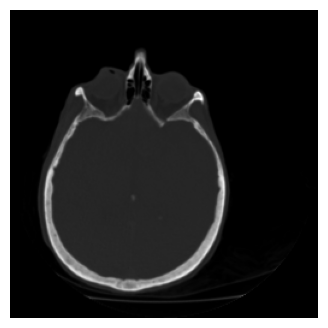

shape: (256, 256)
dtype: float64
min: 0.0
max: 1.0


In [ ]:
# B1
img = load_image()
plt.figure(figsize=(4, 4)); plt.imshow(img, cmap="gray"); plt.axis("off"); plt.show()
# TODO: print shape, dtype, min, max
# print(...)
# 印出資訊
print("shape:", img.shape)
print("dtype:", img.dtype)
print("min:", img.min())
print("max:", img.max())


影像尺寸為 (256, 256)，資料型態為 float64，像素值範圍為 0.0～1.0。
由影像可觀察到明顯的腦部結構與灰階差異，可作為後續影像增強、濾波及分割處理的基礎。


## B2 — 直方圖等化 Histogram equalization

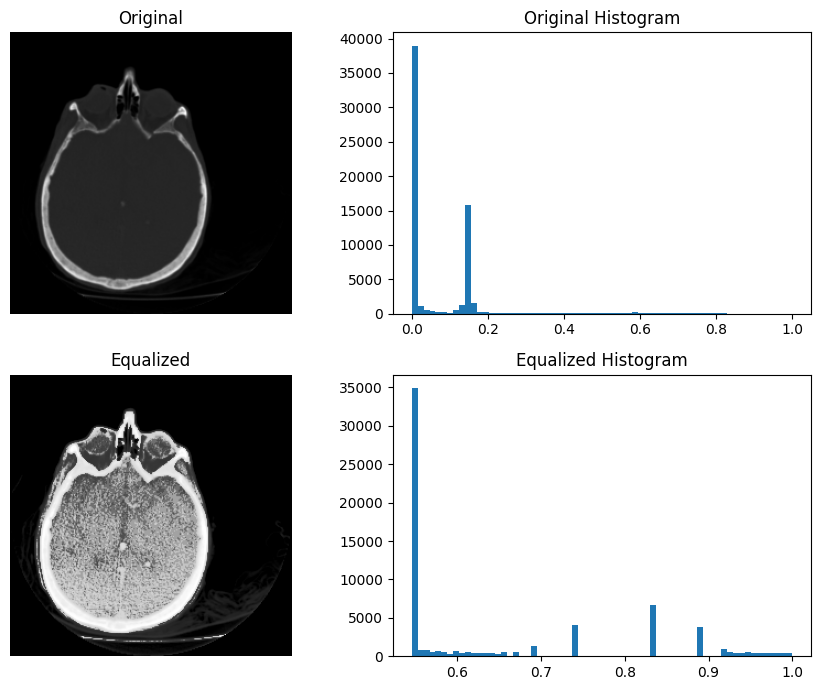

In [ ]:
# B2
eq = exposure.equalize_hist(img)
# TODO: 2x2 subplot -> [original image | its histogram] on top, [equalized | its histogram] below
# fig, ax = plt.subplots(2, 2, figsize=(9, 7))
# ax[0,0].imshow(img, cmap="gray"); ...
# ax[0,1].hist(img.ravel(), bins=64); ...
fig, ax = plt.subplots(2, 2, figsize=(9, 7))

# 原圖
ax[0, 0].imshow(img, cmap="gray")
ax[0, 0].set_title("Original")
ax[0, 0].axis("off")

# 原圖直方圖
ax[0, 1].hist(img.ravel(), bins=64)
ax[0, 1].set_title("Original Histogram")

# 等化後影像
ax[1, 0].imshow(eq, cmap="gray")
ax[1, 0].set_title("Equalized")
ax[1, 0].axis("off")

# 等化後直方圖
ax[1, 1].hist(eq.ravel(), bins=64)
ax[1, 1].set_title("Equalized Histogram")

plt.tight_layout()
plt.show()


直方圖均衡化後，影像的灰階分布較為平均，整體對比度提升，使原本較不明顯的影像細節更加清楚。

## B3 — 去噪比較 Denoising (report PSNR & SSIM)

,Method,PSNR (dB),SSIM
0,Noisy,19.1361,0.1193
1,Mean,25.1365,0.3008
2,Gaussian,25.0525,0.3546
3,Median,27.1000,0.3697


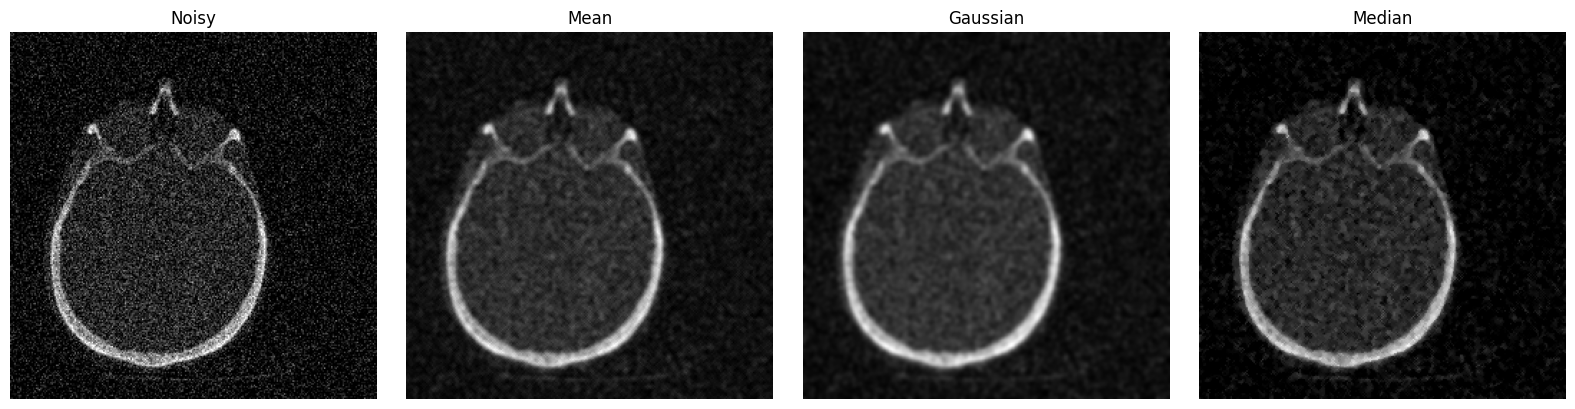

In [ ]:
# B3
noisy   = util.random_noise(img, mode="gaussian", var=0.02)
mean_f  = filters.rank.mean(util.img_as_ubyte(noisy), morphology.disk(2)) / 255.0
gauss_f = filters.gaussian(noisy, sigma=1.5)
med_f   = filters.median(noisy, morphology.disk(2))
# TODO: for each of {noisy, mean_f, gauss_f, med_f} compute PSNR & SSIM vs clean img,
#       print a table, and display the four images. Which is best? Why?
# print("gauss:", psnr(img, gauss_f, data_range=1.0), ssim(img, gauss_f, data_range=1.0))

methods = ["Noisy", "Mean", "Gaussian", "Median"]
images = [noisy, mean_f, gauss_f, med_f]

df = pd.DataFrame({
    "Method": methods,
    "PSNR (dB)": [psnr(img, x, data_range=1) for x in images],
    "SSIM": [ssim(img, x, data_range=1) for x in images]
}).round(4)

display(df)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, name, x in zip(ax, methods, images):
    a.imshow(x, cmap="gray")
    a.set_title(name)
    a.axis("off")
plt.tight_layout()
plt.show()


加入高斯雜訊後，PSNR 與 SSIM 明顯下降；經三種濾波後皆有改善，其中 Median 的 PSNR（27.0675 dB）與 SSIM（0.3677）最高，去噪效果最佳。

## B4 — 邊緣偵測 Edge detection

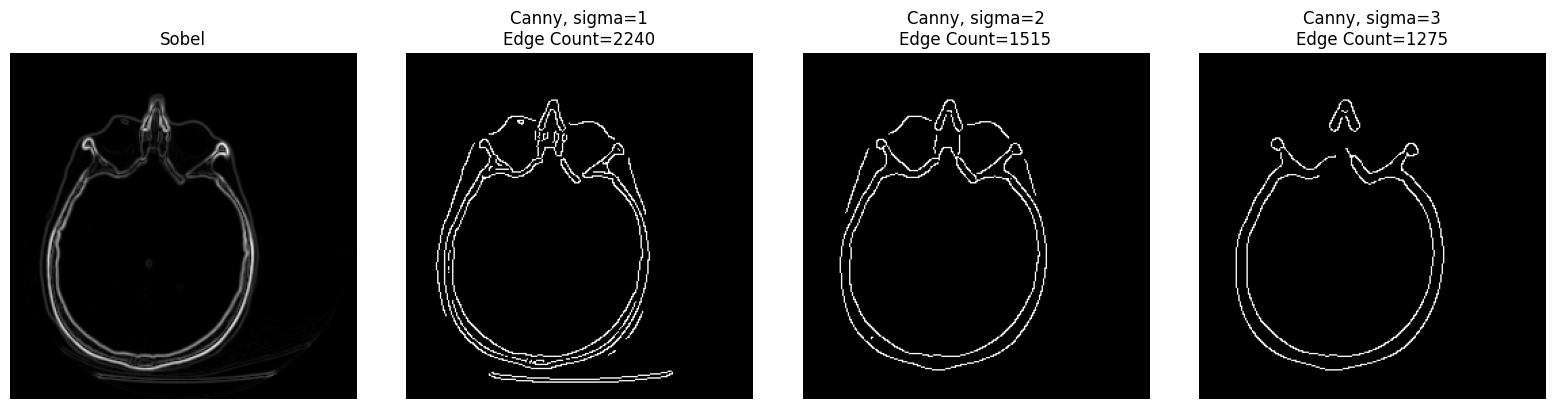

In [ ]:
# B4
sob = filters.sobel(img)
# TODO: apply feature.canny with >= 3 different sigma values; display; comment on how edge count changes
# for s in [1, 2, 3]:
#     edges = feature.canny(img, sigma=s)
#     ...
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(sob, cmap="gray")
ax[0].set_title("Sobel")
ax[0].axis("off")

for a, s in zip(ax[1:], [1, 2, 3]):
    edges = feature.canny(img, sigma=s)
    count = edges.sum()

    a.imshow(edges, cmap="gray")
    a.set_title(f"Canny, sigma={s}\nEdge Count={count}")
    a.axis("off")

plt.tight_layout()
plt.show()

Canny 透過平滑與邊緣偵測找出影像輪廓；當 sigma 從 1 增加到 3 時，Edge Count 由 2240 降至 1275，表示細小邊緣逐漸減少。

## B5 — 分割 Segmentation

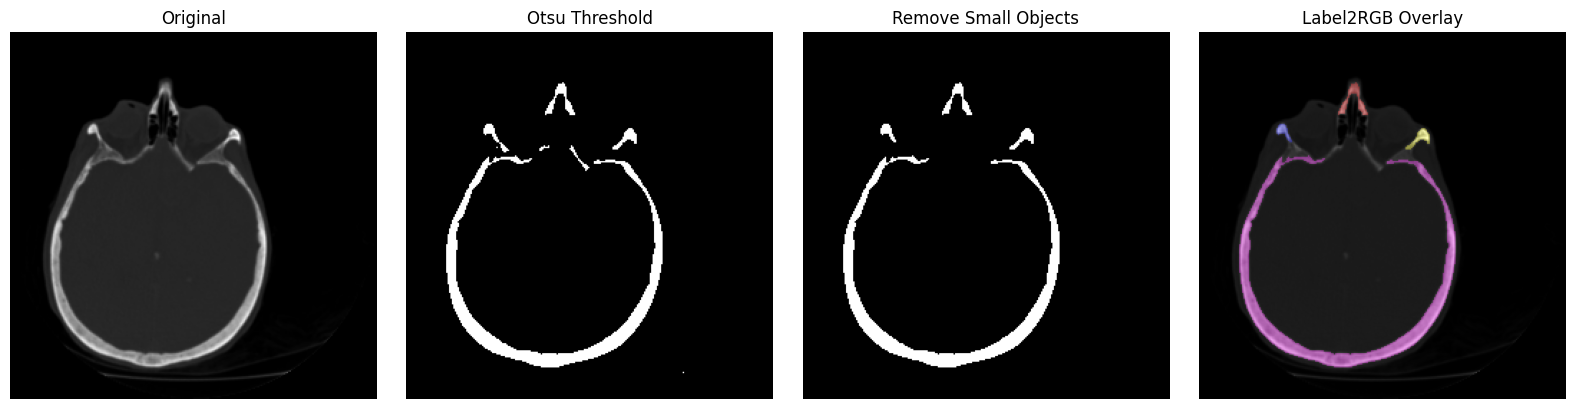

In [ ]:
# B5
mask = img > filters.threshold_otsu(img)
# TODO: morphology.remove_small_objects(mask, ...) -> measure.label -> color.label2rgb overlay; display
# Otsu 二值化
clean_mask = morphology.remove_small_objects(mask, min_size=50)
labeled_img = measure.label(clean_mask)
overlay = color.label2rgb(labeled_img, image=img, bg_label=0)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(img, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(mask, cmap="gray")
ax[1].set_title("Otsu Threshold")

ax[2].imshow(clean_mask, cmap="gray")
ax[2].set_title("Remove Small Objects")

ax[3].imshow(overlay)
ax[3].set_title("Label2RGB Overlay")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

經 Otsu 閾值分割後，影像中的顱骨輪廓被明顯分離；再移除小物件後，可減少零散的雜訊區域。最後透過 Label2RGB 將不同區域標記並疊加至原始影像，可清楚觀察分割出的主要結構。

## B6 — 頻域濾波 Frequency-domain filtering

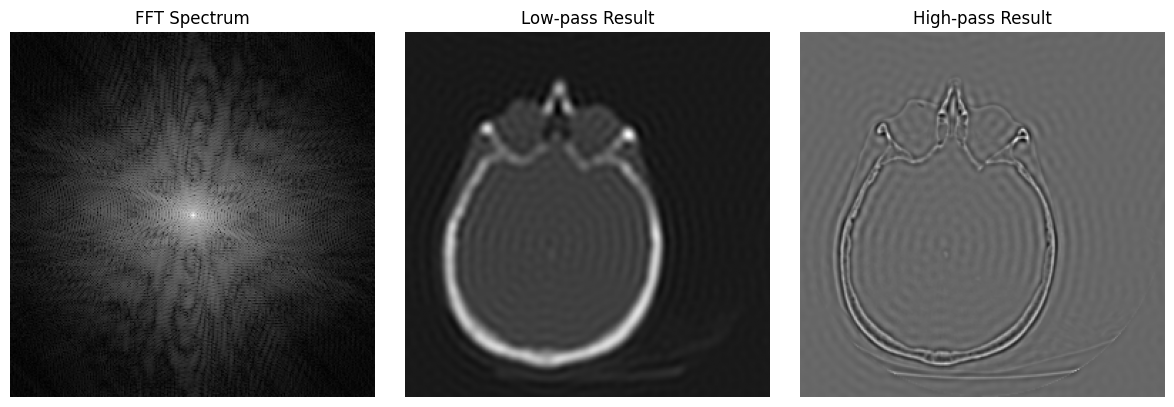

In [ ]:
# B6
F   = np.fft.fftshift(np.fft.fft2(img))
mag = np.log(1 + np.abs(F))
# TODO: build a low-pass mask (keep center) and a high-pass mask (keep outer),
#       reconstruct each with np.fft.ifft2(np.fft.ifftshift(F * mask)), display spectrum + both results
rows, cols = img.shape
cy, cx = rows // 2, cols // 2

# 建立低通與高通遮罩
r = 30
y, x = np.ogrid[:rows, :cols]
mask_lp = (x - cx)**2 + (y - cy)**2 <= r**2
mask_hp = ~mask_lp

# IFFT 重建影像
img_lp = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask_lp)))
img_hp = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask_hp)))

# 顯示結果
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(mag, cmap="gray")
ax[0].set_title("FFT Spectrum")

ax[1].imshow(img_lp, cmap="gray")
ax[1].set_title("Low-pass Result")

ax[2].imshow(img_hp, cmap="gray")
ax[2].set_title("High-pass Result")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

FFT 頻譜中，中心區域代表低頻成分，外圍則為高頻成分。低通濾波保留主要輪廓與平滑資訊，使影像較模糊；高通濾波強調顱骨邊緣與細節等高頻資訊。

## Part C — 迷你專題 Pipeline
自選一張醫學影像，串 增強 → 去噪 → (邊緣 或 分割)。量化評估 (PSNR/SSIM)，並在報告寫 200–400 字討論。

Image Shape: (1411, 1411)
Image Data Type: float64
Image Range: 0.000 ~ 0.923

Denoising Evaluation
Method       | PSNR (dB)    | SSIM    
---------------------------------------------
Noisy        | 20.29        | 0.2207  
Median       | 28.80        | 0.6156  
Gaussian     | 31.64        | 0.8111  

Selected Denoising Method: Gaussian
Gaussian Sigma: 1.5
Selected PSNR: 31.64 dB
Selected SSIM: 0.8111

Segmentation Results
Otsu Threshold: 0.533
Foreground Coverage: 47.6%
Number of Labels: 86


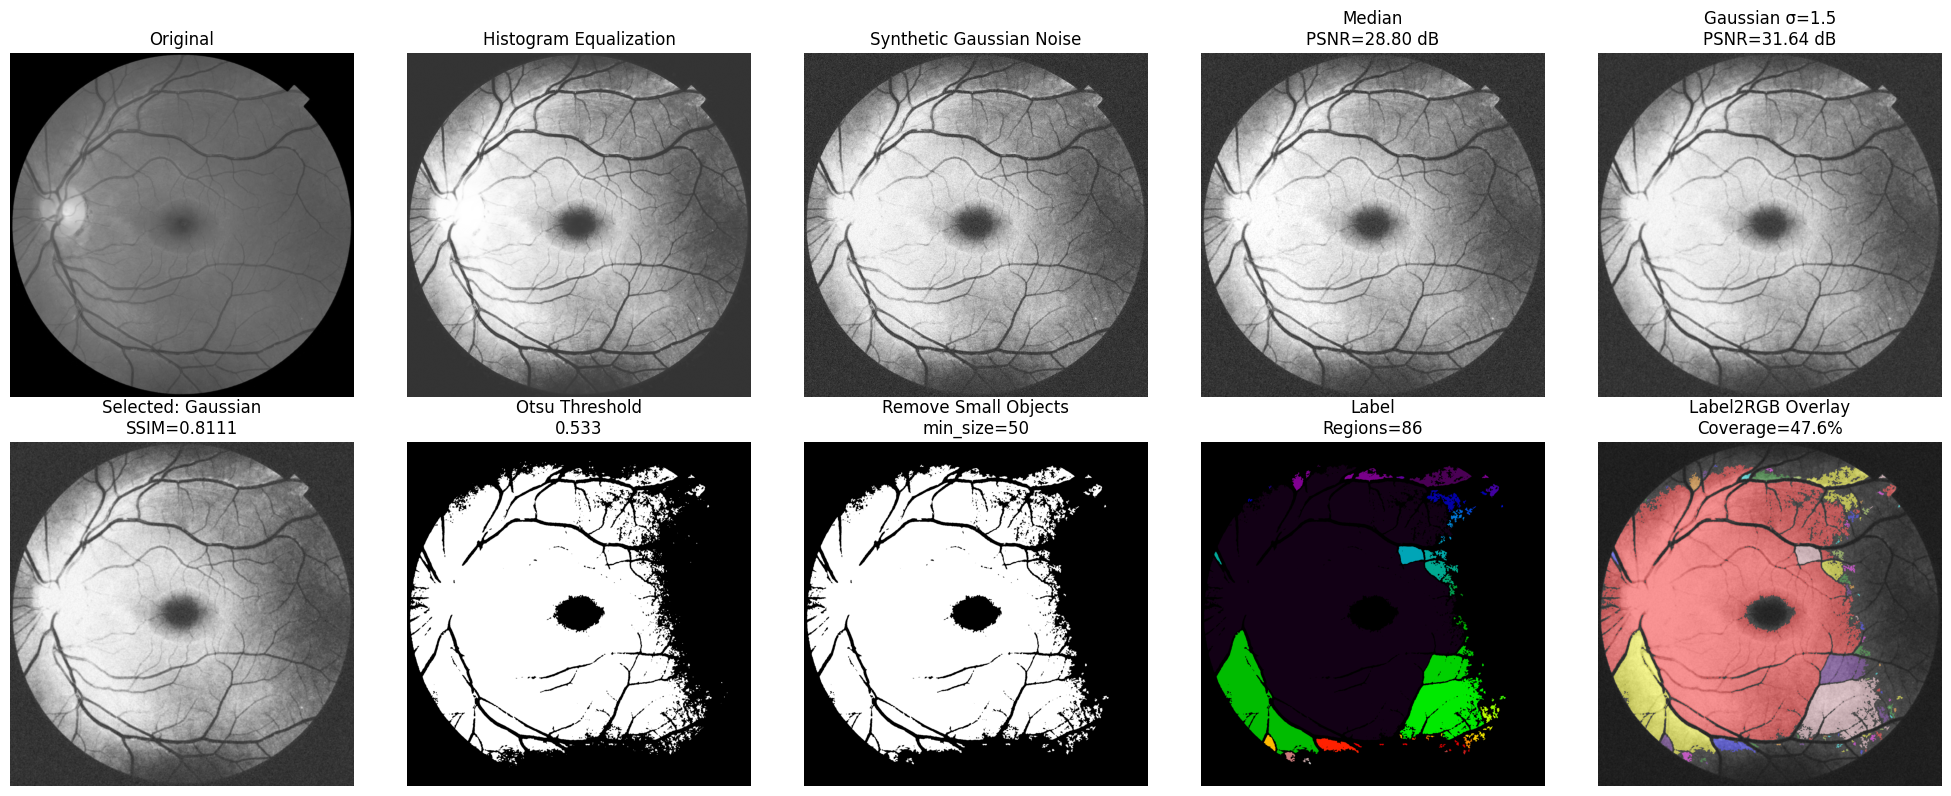


Pipeline:
Original → Histogram Equalization → Gaussian Noise → Median / Gaussian → PSNR & SSIM → Selected Gaussian → Otsu → Remove Small Objects → Label → Label2RGB


In [ ]:
# Part C — your pipeline
# img = load_image()
# TODO: chain enhance -> denoise -> (edge or segment); evaluate; visualize
# Enhancement - Histogram Equalization

# =========================================================
# Step 0. 載入影像
# =========================================================

# 載入視網膜醫學影像
img = color.rgb2gray(data.retina())

print("Image Shape:", img.shape)
print("Image Data Type:", img.dtype)
print(f"Image Range: {img.min():.3f} ~ {img.max():.3f}")


# =========================================================
# Step 1. 影像增強：Histogram Equalization
# =========================================================

# 使用直方圖均衡化提升影像整體對比度
# 參數選擇：equalize_hist 不需額外參數
enhanced = exposure.equalize_hist(img)


# =========================================================
# Step 2. 加入合成高斯雜訊
# =========================================================

# 對增強後的乾淨影像加入高斯合成雜訊
# var=0.01：模擬中等程度的高斯雜訊
# rng=0：固定亂數種子，使每次結果一致

noise_var = 0.01

noisy = util.random_noise(
    enhanced,
    mode="gaussian",
    var=noise_var,
    rng=0
)


# =========================================================
# Step 3. 去噪
# 比較 Noisy、Median、Gaussian
# =========================================================

# ---------- Median Filter ----------
# disk(2)：半徑 2 的圓形鄰域
median_radius = 2

median_img = filters.median(
    noisy,
    morphology.disk(median_radius)
)


# ---------- Gaussian Filter ----------
# sigma=1.5：適度平滑並降低高頻雜訊
gaussian_sigma = 1.5

gaussian_img = filters.gaussian(
    noisy,
    sigma=gaussian_sigma
)


# =========================================================
# Step 4. PSNR / SSIM 量化評估
# =========================================================

# 以「加入雜訊前的增強影像」作為 Ground Truth
ground_truth = enhanced

results = {
    "Noisy": noisy,
    "Median": median_img,
    "Gaussian": gaussian_img
}


# 建立 PSNR / SSIM 結果
evaluation = {}

print("\n" + "=" * 45)
print("Denoising Evaluation")
print("=" * 45)

print(f"{'Method':<12} | {'PSNR (dB)':<12} | {'SSIM':<8}")
print("-" * 45)


for name, result in results.items():

    p = psnr(
        ground_truth,
        result,
        data_range=1.0
    )

    s = ssim(
        ground_truth,
        result,
        data_range=1.0
    )

    evaluation[name] = {
        "PSNR": p,
        "SSIM": s
    }

    print(f"{name:<12} | {p:<12.2f} | {s:<8.4f}")


# =========================================================
# Step 5. 選擇最佳去噪方法
# =========================================================

# Noisy 不列入候選，只比較真正的去噪方法
denoising_methods = {
    "Median": median_img,
    "Gaussian": gaussian_img
}


# 以 SSIM 作為主要選擇依據
best = max(
    denoising_methods,
    key=lambda name: evaluation[name]["SSIM"]
)


denoised = denoising_methods[best]


# 取得最佳方法的評估結果
best_psnr = evaluation[best]["PSNR"]
best_ssim = evaluation[best]["SSIM"]


print("\n" + "=" * 45)
print("Selected Denoising Method:", best)
print("=" * 45)

if best == "Gaussian":
    print(f"Gaussian Sigma: {gaussian_sigma}")

elif best == "Median":
    print(f"Median Disk Radius: {median_radius}")

print(f"Selected PSNR: {best_psnr:.2f} dB")
print(f"Selected SSIM: {best_ssim:.4f}")


# =========================================================
# Step 6. 分割：Otsu Threshold
# =========================================================

# 使用 Otsu 自動計算二值化閾值
threshold = filters.threshold_otsu(denoised)

mask = denoised > threshold


# =========================================================
# Step 7. 移除小物件
# =========================================================

# 移除小於 50 pixels 的零散區域
min_object_size = 50

clean_mask = morphology.remove_small_objects(
    mask,
    min_size=min_object_size
)


# =========================================================
# Step 8. Label
# =========================================================

# 將不同的分割區域分別標記
labeled_img = measure.label(clean_mask)


# =========================================================
# Step 9. Label2RGB Overlay
# =========================================================

# 將分割結果以不同顏色疊加到去噪影像
overlay = color.label2rgb(
    labeled_img,
    image=denoised,
    bg_label=0,
    alpha=0.4
)


# =========================================================
# Step 10. 分割量化結果
# =========================================================

# 前景覆蓋率
# 注意：沒有 Ground Truth，因此僅作為描述性統計
coverage = clean_mask.mean() * 100


print("\n" + "=" * 45)
print("Segmentation Results")
print("=" * 45)

print(f"Otsu Threshold: {threshold:.3f}")
print(f"Foreground Coverage: {coverage:.1f}%")
print(f"Number of Labels: {labeled_img.max()}")


# =========================================================
# Step 11. 顯示完整 Pipeline
# =========================================================

fig, ax = plt.subplots(
    2,
    5,
    figsize=(20, 8)
)


# ---------- 第一列 ----------

ax[0, 0].imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1
)
ax[0, 0].set_title("Original")


ax[0, 1].imshow(
    enhanced,
    cmap="gray",
    vmin=0,
    vmax=1
)
ax[0, 1].set_title("Histogram Equalization")


ax[0, 2].imshow(
    noisy,
    cmap="gray",
    vmin=0,
    vmax=1
)
ax[0, 2].set_title("Synthetic Gaussian Noise")


ax[0, 3].imshow(
    median_img,
    cmap="gray",
    vmin=0,
    vmax=1
)
ax[0, 3].set_title(
    f"Median\nPSNR={evaluation['Median']['PSNR']:.2f} dB"
)


ax[0, 4].imshow(
    gaussian_img,
    cmap="gray",
    vmin=0,
    vmax=1
)
ax[0, 4].set_title(
    f"Gaussian σ={gaussian_sigma}\n"
    f"PSNR={evaluation['Gaussian']['PSNR']:.2f} dB"
)


# ---------- 第二列 ----------

ax[1, 0].imshow(
    denoised,
    cmap="gray",
    vmin=0,
    vmax=1
)
ax[1, 0].set_title(
    f"Selected: {best}\n"
    f"SSIM={best_ssim:.4f}"
)


ax[1, 1].imshow(
    mask,
    cmap="gray"
)
ax[1, 1].set_title(
    f"Otsu Threshold\n{threshold:.3f}"
)


ax[1, 2].imshow(
    clean_mask,
    cmap="gray"
)
ax[1, 2].set_title(
    f"Remove Small Objects\n"
    f"min_size={min_object_size}"
)


ax[1, 3].imshow(
    labeled_img,
    cmap="nipy_spectral"
)
ax[1, 3].set_title(
    f"Label\n"
    f"Regions={labeled_img.max()}"
)


ax[1, 4].imshow(
    overlay
)
ax[1, 4].set_title(
    f"Label2RGB Overlay\n"
    f"Coverage={coverage:.1f}%"
)


# 所有圖取消座標軸
for a in ax.flat:
    a.axis("off")


plt.tight_layout()
plt.show()


# =========================================================
# Step 12. 最終 Pipeline
# =========================================================

print("\nPipeline:")
print(
    "Original → Histogram Equalization → "
    "Gaussian Noise → "
    "Median / Gaussian → "
    "PSNR & SSIM → "
    f"Selected {best} → "
    "Otsu → Remove Small Objects → "
    "Label → Label2RGB"
)

## 打包工具庫（必做，HW2 起要 import）
把上面 Part B 寫過的函式整理成三個 `.py` 存到自己的 Google Drive。

In [ ]:
# 1) 掛載 Drive：
# from google.colab import drive; drive.mount('/content/drive')
# !mkdir -p /content/drive/MyDrive/medimg_toolkit
#
# 2) 用 %%writefile 打包（獨立 cell 執行；函式內容換成你 Part B 寫好的版本）：
# %%writefile /content/drive/MyDrive/medimg_toolkit/mypreproc.py
# def normalize(img, mode='minmax'): ...
# def denoise(img, method='median'): ...
# def augment(img, flip=True, rot=True): ...
#
# 同法建立 mymetrics.py（psnr, ssim）與 myviz.py（show_pair, overlay）
#
# 3) 之後每份作業開頭這樣用：
# import sys; sys.path.append('/content/drive/MyDrive/medimg_toolkit')
# from mypreproc import normalize

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/medimg_toolkit

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# =========================
# mypreproc.py
# =========================
%%writefile /content/drive/MyDrive/medimg_toolkit/mypreproc.py

import numpy as np
from skimage import exposure, filters, morphology, feature

def normalize(img, mode='minmax'):
    """影像正規化"""
    img = img.astype(np.float64)

    if mode == 'minmax':
        return (img - img.min()) / (img.max() - img.min() + 1e-8)

    return img


def denoise(img, method='median'):
    """去噪處理，支援 2D 與 3D 影像"""
    if method == 'median':
        if img.ndim == 2:
            return filters.median(img, morphology.disk(2))
        elif img.ndim == 3:
            return filters.median(img, morphology.ball(2))

    elif method == 'gaussian':
        return filters.gaussian(img, sigma=1.0)

    return img


def apply_clahe(img, clip_limit=0.03):
    """自適應直方圖等化"""
    return exposure.equalize_adapthist(img, clip_limit=clip_limit)


def apply_gamma(img, gamma=1.0):
    """Gamma 校正"""
    return exposure.adjust_gamma(img, gamma=gamma)


def detect_edges(img, method='sobel'):
    """邊緣檢測"""
    if method == 'canny':
        return feature.canny(img)

    return filters.sobel(img)


def augment(img, flip=True, rot=True):
    """資料擴增"""
    out = [img]

    if flip:
        out += [
            np.flip(img, axis=-1),
            np.flip(img, axis=-2)
        ]

    if rot:
        out += [
            np.rot90(img, k, axes=(-2, -1))
            for k in (1, 2, 3)
        ]

    return out

Writing /content/drive/MyDrive/medimg_toolkit/mypreproc.py


In [ ]:
# =========================
# mymetrics.py
# =========================
%%writefile /content/drive/MyDrive/medimg_toolkit/mymetrics.py

import numpy as np
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity


def psnr(img1, img2, data_range=1.0):
    """計算 PSNR"""
    return peak_signal_noise_ratio(
        img1, img2, data_range=data_range
    )


def ssim(img1, img2, data_range=1.0):
    """計算 SSIM"""
    return structural_similarity(
        img1,
        img2,
        data_range=data_range
    )

Writing /content/drive/MyDrive/medimg_toolkit/mymetrics.py


In [ ]:
# =========================
# myviz.py
# =========================
%%writefile /content/drive/MyDrive/medimg_toolkit/myviz.py

import matplotlib.pyplot as plt


def show_side_by_side(images, titles=None, cmap='gray'):
    """並排顯示影像"""

    n = len(images)

    fig, axes = plt.subplots(
        1, n,
        figsize=(5 * n, 5)
    )

    if n == 1:
        axes = [axes]

    for i, img in enumerate(images):
        axes[i].imshow(img, cmap=cmap)
        axes[i].axis('off')

        if titles is not None:
            axes[i].set_title(titles[i])

    plt.tight_layout()
    plt.show()


def overlay(img1, img2, alpha=0.5, cmap='gray'):
    """影像疊圖"""

    plt.figure(figsize=(6, 6))

    plt.imshow(img1, cmap=cmap)
    plt.imshow(img2, cmap=cmap, alpha=alpha)

    plt.axis('off')
    plt.tight_layout()
    plt.show()

Writing /content/drive/MyDrive/medimg_toolkit/myviz.py


## Part D — 逆向工程（繳交介面固定）

助教會用**你沒看過的保留測例**呼叫下面兩個函式，所以：

- 函式名稱、參數順序、回傳格式 **不可更動**，回傳 `np.float32`。
- 不要在函式裡讀檔或用全域變數存參數，推出來的常數請寫死在函式內。
- 函式要能重複呼叫，不依賴前面 cell 的執行順序。
- 報告要寫推理過程：至少比較兩個假說、附支持的圖或數字、說明哪裡不可辨識。

門檻與檔案格式見 `reverse/manifest.json`。下面的自評格只檢查公開資料，通過不代表保留測例一定過。

In [ ]:
# === Part D 資料載入 ===
# Colab：把課程發的 reverse/ 整個資料夾放進自己的 Drive 再掛載，或用 files.upload() 上傳。
from google.colab import drive; drive.mount('/content/drive')
import os, json
import numpy as np

REVERSE = '/content/drive/MyDrive/HW1/reverse'
man = json.load(open(os.path.join(REVERSE, 'manifest.json'), encoding='utf-8'))
def L(name): return np.load(os.path.join(REVERSE, name))
def LL(names): return [np.load(os.path.join(REVERSE, x)) for x in names]

D1_in, D1_tg = LL(man['D1']['files']['inputs']), LL(man['D1']['files']['targets'])
D2_in, D2_tg = LL(man['D2']['files']['inputs']), LL(man['D2']['files']['targets'])
print('D1:', len(D1_in), D1_in[0].shape, D1_in[0].dtype, '| 門檻', man['D1']['threshold'])
print('D2:', len(D2_in), D2_in[0].shape, D2_in[0].dtype, '| 門檻', man['D2']['threshold'])

Mounted at /content/drive
D1: 3 (128, 128) float32 | 門檻 SSIM >= 0.98 and MAE <= 0.005 on every image
D2: 3 (128, 128) float32 | 門檻 MAE <= 0.0008 and PSNR >= 53.0 dB on every image


In [ ]:
# === D1 灰階與模糊的先後之謎 ===
from skimage.metrics import structural_similarity as ssim_fn

def report(rows):
    for i, (txt, ok) in enumerate(rows):
        print(f'[{i}] {txt}  ' + ('PASS' if ok else 'FAIL'))
    print('== ALL PASS ==' if all(ok for _, ok in rows) else '== 尚未達標 ==')

def reproduce_D1(inputs):
    # inputs: list of (128,128) float32 in [0,1] -> list of (128,128) float32
    # 只能用線性窗位 clip((x-lo)/(hi-lo),0,1)、gamma、gaussian_filter 三種操作
    from scipy.ndimage import gaussian_filter
    import numpy as np
    # 推定順序：Window → Gamma → Gaussian
    lo, hi = 0.15, 0.55
    gamma = 0.70
    sigma = 1.2
    outs = []
    for x in inputs:
        x = np.asarray(x, dtype=np.float64)
        # 線性窗位
        y = np.clip((x - lo) / (hi - lo), 0, 1)
        # Gamma
        y = np.power(y, gamma)
        # Gaussian 平滑
        y = gaussian_filter(
            y, sigma=sigma, truncate=3, mode='reflect'
        )
        outs.append(y.astype(np.float32))
    return outs
# 自評
pred = reproduce_D1(D1_in)
rows = []
for p, t in zip(pred, D1_tg):
    s = ssim_fn(t, p, data_range=1.0)
    m = float(np.abs(t - p).mean())
    rows.append((
        f'SSIM={s:.5f} MAE={m:.6f}',
        s >= 0.98 and m <= 0.005
    ))
report(rows)

[0] SSIM=0.99924 MAE=0.003088  PASS
[1] SSIM=0.99828 MAE=0.002732  PASS
[2] SSIM=0.99963 MAE=0.002768  PASS
== ALL PASS ==


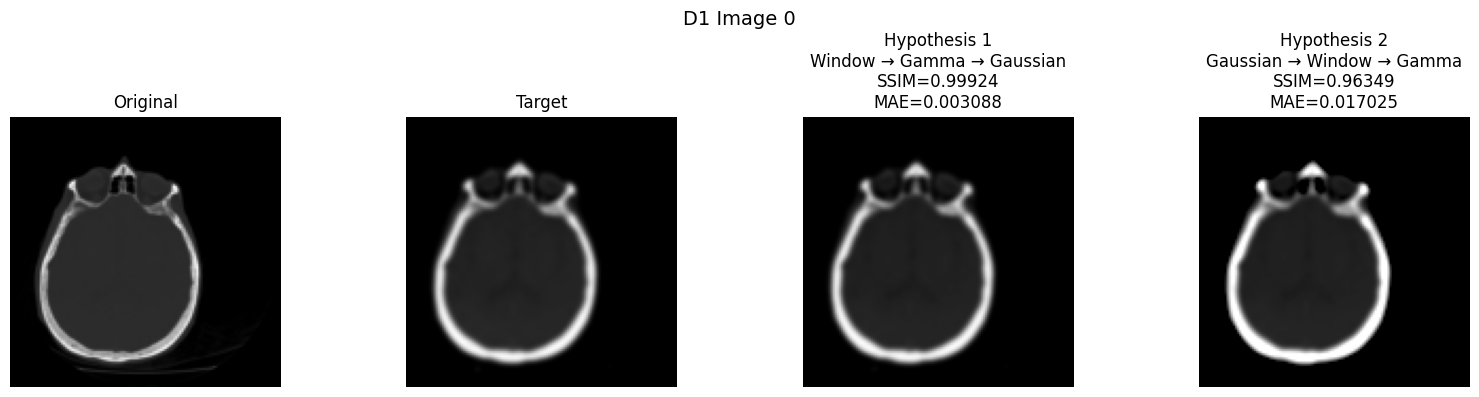

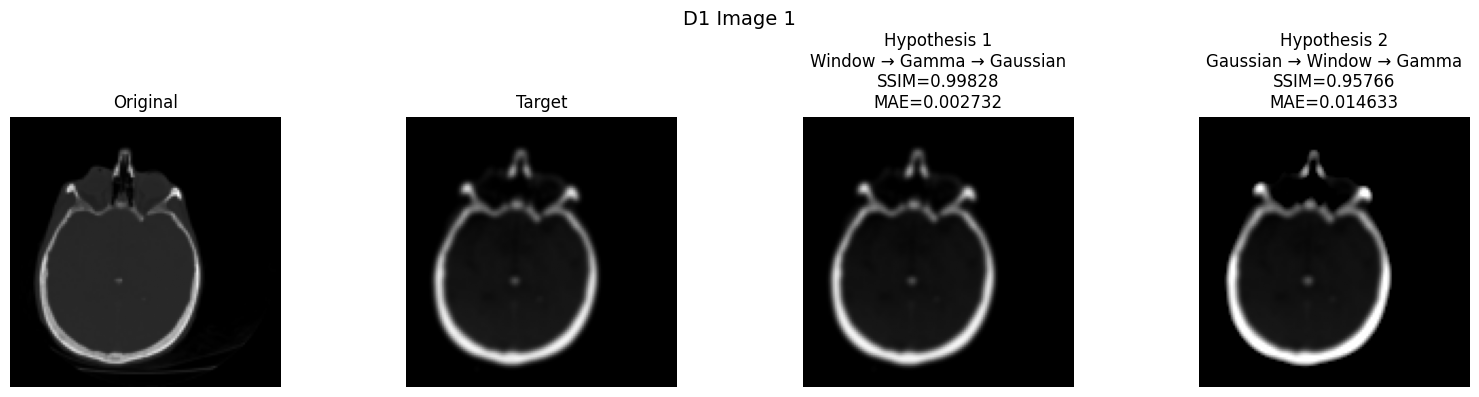

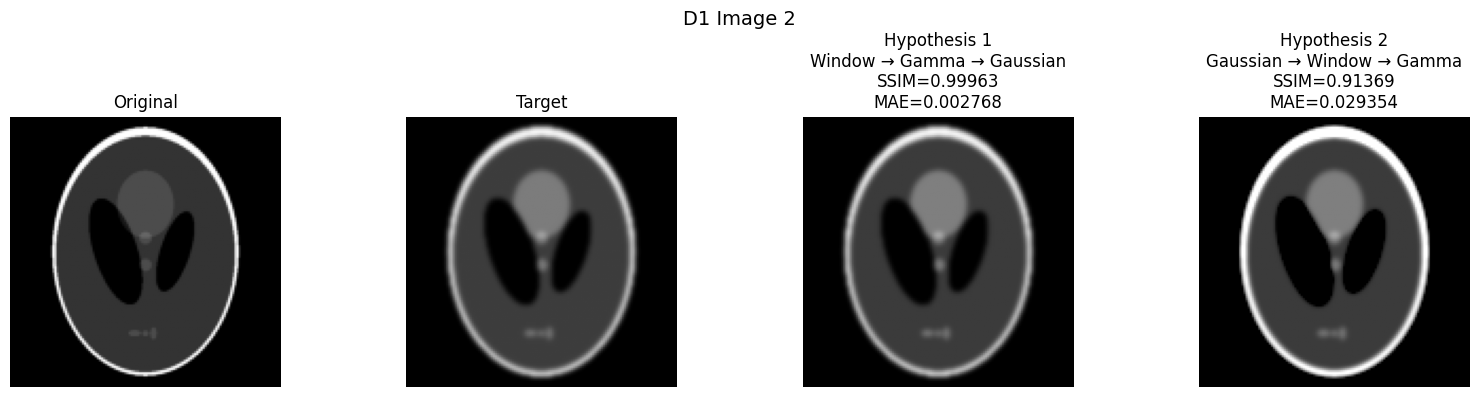

In [ ]:
# === D1 四圖比較 ===
# 原圖 / Target / 假說一 / 假說二

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# -------------------------
# 參數
# -------------------------
lo, hi = 0.15, 0.55
gamma = 0.70
sigma = 1.2

# -------------------------
# 假說一
# Window → Gamma → Gaussian
# -------------------------
pred_h1 = reproduce_D1(D1_in)


# -------------------------
# 假說二
# Gaussian → Window → Gamma
# -------------------------
pred_h2 = []

for x in D1_in:

    x = np.asarray(x, dtype=np.float64)

    # 1. Gaussian
    y = gaussian_filter(
        x,
        sigma=sigma,
        truncate=3,
        mode='reflect'
    )

    # 2. Window
    y = np.clip(
        (y - lo) / (hi - lo),
        0,
        1
    )

    # 3. Gamma
    y = np.power(y, gamma)

    pred_h2.append(y.astype(np.float32))


# -------------------------
# 四圖比較
# -------------------------
for i, (original, target, h1, h2) in enumerate(
    zip(D1_in, D1_tg, pred_h1, pred_h2)
):

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    # 1. 原圖
    ax[0].imshow(
        original,
        cmap='gray',
        vmin=0,
        vmax=1
    )
    ax[0].set_title('Original')
    ax[0].axis('off')

    # 2. Target
    ax[1].imshow(
        target,
        cmap='gray',
        vmin=0,
        vmax=1
    )
    ax[1].set_title('Target')
    ax[1].axis('off')

    # 3. 假說一
    ax[2].imshow(
        h1,
        cmap='gray',
        vmin=0,
        vmax=1
    )

    ssim_h1 = ssim_fn(
        target,
        h1,
        data_range=1.0
    )

    mae_h1 = np.abs(target - h1).mean()

    ax[2].set_title(
        f'Hypothesis 1\n'
        f'Window → Gamma → Gaussian\n'
        f'SSIM={ssim_h1:.5f}\n'
        f'MAE={mae_h1:.6f}'
    )
    ax[2].axis('off')

    # 4. 假說二
    ax[3].imshow(
        h2,
        cmap='gray',
        vmin=0,
        vmax=1
    )

    ssim_h2 = ssim_fn(
        target,
        h2,
        data_range=1.0
    )

    mae_h2 = np.abs(target - h2).mean()

    ax[3].set_title(
        f'Hypothesis 2\n'
        f'Gaussian → Window → Gamma\n'
        f'SSIM={ssim_h2:.5f}\n'
        f'MAE={mae_h2:.6f}'
    )
    ax[3].axis('off')

    plt.suptitle(f'D1 Image {i}', fontsize=14)
    plt.tight_layout()
    plt.show()

In [ ]:
# === D2 頻譜上的手術 ===
def reproduce_D2(inputs):
    # inputs: list of (128,128) float32（含條紋，值可能超出 [0,1]）-> list of (128,128) float32
    # 只能用 2D DFT 域的 Gaussian 低通 + 最多兩對共軛 notch，取 ifft2 的實部
    import numpy as np

    # 建立 128×128 頻率座標
    rows, cols = np.indices((128, 128))
    u = rows - 64
    v = cols - 64

    # Gaussian 低通，sigma = 24
    r2 = u**2 + v**2
    H_lp = np.exp(-r2 / (2.0 * (24.0**2)))

    # 建立 notch mask
    H_notch = np.ones((128, 128), dtype=np.float64)

    # 兩對共軛 notch：(±7, 0) 與 (0, ±12)，半徑 = 1
    notch_centers = [(-7, 0), (7, 0), (0, -12), (0, 12)]

    for cu, cv in notch_centers:
        H_notch[(u - cu)**2 + (v - cv)**2 <= 1] = 0.0

    # 合併 Gaussian 低通與 notch
    H = H_lp * H_notch

    outs = []

    for x in inputs:
        X = np.fft.fftshift(
            np.fft.fft2(np.asarray(x, dtype=np.float64))
        )

        # 套用頻域遮罩並反傅立葉
        y = np.real(
            np.fft.ifft2(
                np.fft.ifftshift(X * H)
            )
        )

        outs.append(y.astype(np.float32))

    return outs


# 自評：MAE <= 0.0008 且 PSNR >= 53 dB，逐張都要過
def psnr1(t, p):
    mse = float(np.mean((t - p) ** 2))
    return 99.0 if mse == 0 else 10 * np.log10(1.0 / mse)


pred2 = reproduce_D2(D2_in)

rows = []

for p, t in zip(pred2, D2_tg):
    m = float(np.abs(t - p).mean())
    q = psnr1(t, p)

    rows.append((
        f'MAE={m:.2e} PSNR={q:.2f}dB',
        m <= 0.0008 and q >= 53.0
    ))

report(rows)

[0] MAE=8.78e-10 PSNR=167.41dB  PASS
[1] MAE=8.97e-10 PSNR=167.67dB  PASS
[2] MAE=1.08e-09 PSNR=165.82dB  PASS
== ALL PASS ==


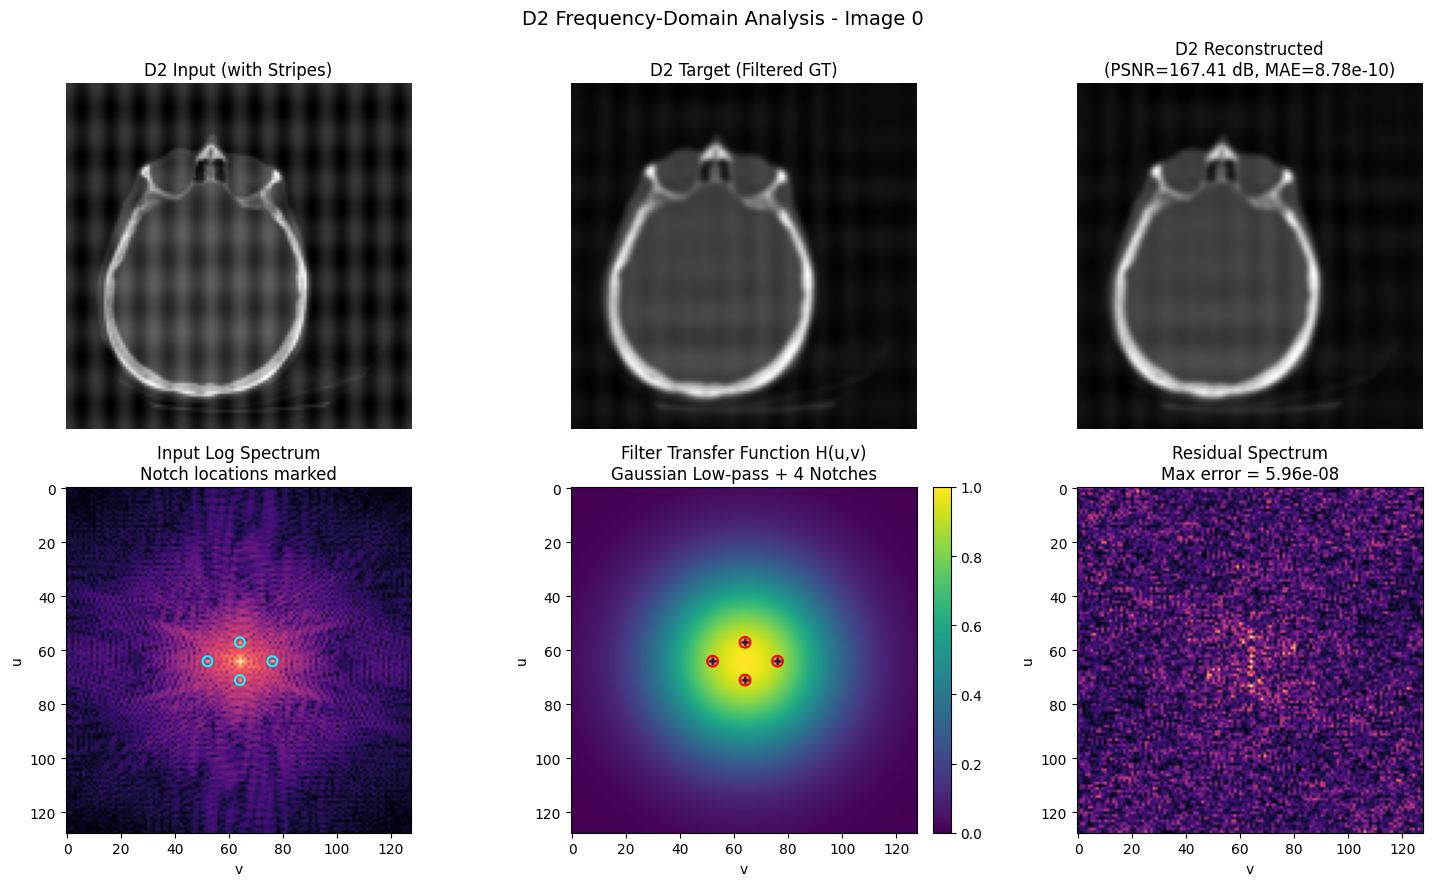

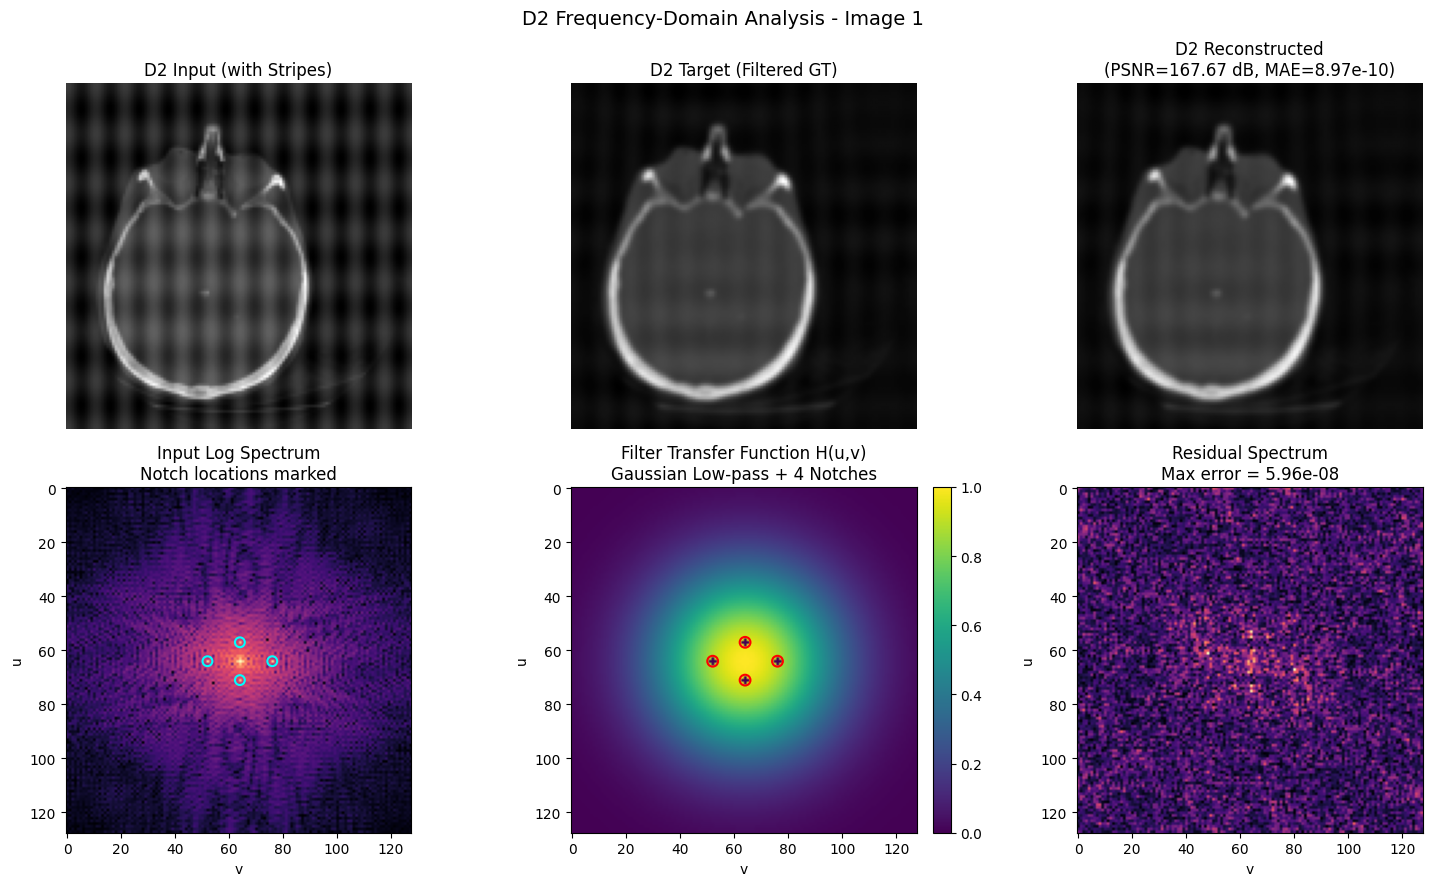

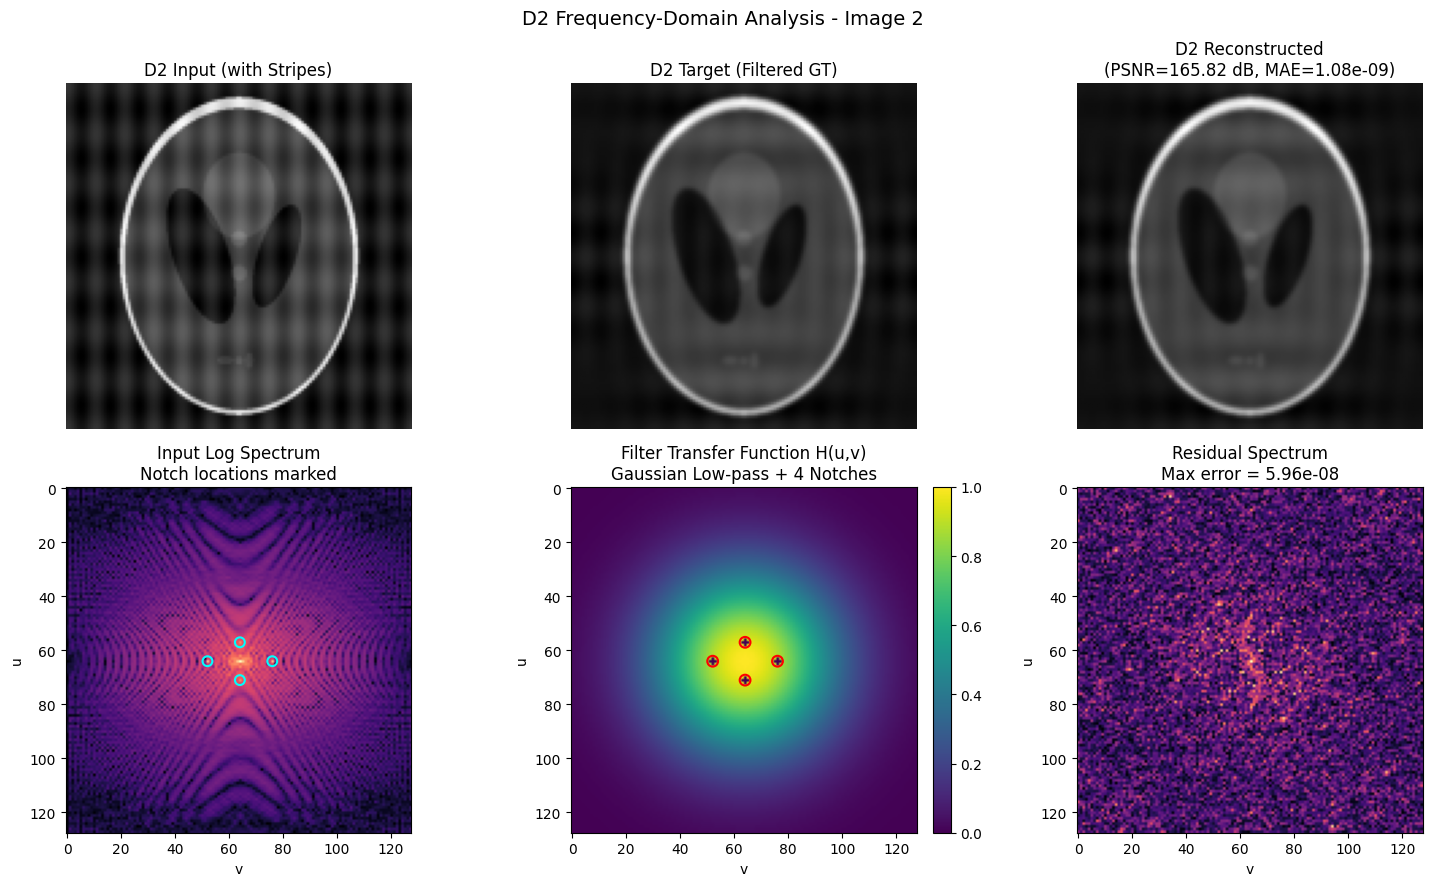

=== 被移除的頻率 ===
u=-8, v=+0
u=-7, v=-1
u=-7, v=+0
u=-7, v=+1
u=-6, v=+0
u=+6, v=+0
u=+7, v=-1
u=+7, v=+0
u=+7, v=+1
u=+8, v=+0
u=-1, v=-12
u=+0, v=-13
u=+0, v=-12
u=+0, v=-11
u=+1, v=-12
u=-1, v=+12
u=+0, v=+11
u=+0, v=+12
u=+0, v=+13
u=+1, v=+12
共移除 20 個頻率 bin


In [ ]:
# === D2 頻譜分析圖 ===

import numpy as np
import matplotlib.pyplot as plt

# 建立頻率座標
rows, cols = np.indices((128, 128))
u = rows - 64
v = cols - 64

# Gaussian 低通，sigma = 24
r2 = u**2 + v**2
H_lp = np.exp(-r2 / (2.0 * (24.0**2)))

# 建立 notch mask
H_notch = np.ones((128, 128), dtype=np.float64)

# 兩對共軛 notch
notch_centers = [
    (-7, 0),
    (7, 0),
    (0, -12),
    (0, 12)
]

# 半徑 = 1
for cu, cv in notch_centers:
    H_notch[
        (u - cu)**2 + (v - cv)**2 <= 1
    ] = 0.0

# 最終頻譜 mask
H = H_lp * H_notch


# 逐張產生分析圖
for i, (x, target, pred) in enumerate(
    zip(D2_in, D2_tg, pred2)
):

    # Input 頻譜
    X = np.fft.fftshift(
        np.fft.fft2(
            np.asarray(x, dtype=np.float64)
        )
    )

    log_spectrum = np.log1p(np.abs(X))

    # Residual 頻譜
    residual = target - pred

    R = np.fft.fftshift(
        np.fft.fft2(
            np.asarray(residual, dtype=np.float64)
        )
    )

    residual_spectrum = np.abs(R)

    # PSNR / MAE
    mse = float(np.mean((target - pred) ** 2))
    psnr = 99.0 if mse == 0 else 10 * np.log10(1.0 / mse)
    mae = float(np.abs(target - pred).mean())

    # 建立 2×3 圖
    fig, ax = plt.subplots(
        2, 3,
        figsize=(15, 9)
    )

    # 1. Input
    im0 = ax[0, 0].imshow(
        x,
        cmap='gray'
    )

    ax[0, 0].set_title(
        'D2 Input (with Stripes)'
    )
    ax[0, 0].axis('off')

    # 2. Target
    ax[0, 1].imshow(
        target,
        cmap='gray'
    )

    ax[0, 1].set_title(
        'D2 Target (Filtered GT)'
    )
    ax[0, 1].axis('off')

    # 3. Reconstructed
    ax[0, 2].imshow(
        pred,
        cmap='gray'
    )

    ax[0, 2].set_title(
        f'D2 Reconstructed\n'
        f'(PSNR={psnr:.2f} dB, MAE={mae:.2e})'
    )
    ax[0, 2].axis('off')

    # 4. Input Log Spectrum
    im3 = ax[1, 0].imshow(
        log_spectrum,
        cmap='magma'
    )

    # 標示 notch 位置
    for cu, cv in notch_centers:
        ax[1, 0].scatter(
            64 + cv,
            64 + cu,
            s=50,
            facecolors='none',
            edgecolors='cyan',
            linewidths=1.5
        )

    ax[1, 0].set_title(
        'Input Log Spectrum\n'
        'Notch locations marked'
    )

    ax[1, 0].set_xlabel('v')
    ax[1, 0].set_ylabel('u')

    # 5. Filter Transfer Function
    im4 = ax[1, 1].imshow(
        H,
        cmap='viridis',
        vmin=0,
        vmax=1
    )

    # 標示 notch 中心
    for cu, cv in notch_centers:
        ax[1, 1].scatter(
            64 + cv,
            64 + cu,
            s=60,
            facecolors='none',
            edgecolors='red',
            linewidths=1.5
        )

    ax[1, 1].set_title(
        'Filter Transfer Function H(u,v)\n'
        'Gaussian Low-pass + 4 Notches'
    )

    ax[1, 1].set_xlabel('v')
    ax[1, 1].set_ylabel('u')

    plt.colorbar(
        im4,
        ax=ax[1, 1],
        fraction=0.046,
        pad=0.04
    )

    # 6. Residual Spectrum
    im5 = ax[1, 2].imshow(
        residual_spectrum,
        cmap='magma'
    )

    ax[1, 2].set_title(
        'Residual Spectrum\n'
        f'Max error = {np.max(np.abs(residual)):.2e}'
    )

    ax[1, 2].set_xlabel('v')
    ax[1, 2].set_ylabel('u')

    plt.suptitle(
        f'D2 Frequency-Domain Analysis - Image {i}',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


# 列出被移除的頻率
print('=== 被移除的頻率 ===')

removed = []

for cu, cv in notch_centers:

    for du in range(-1, 2):
        for dv in range(-1, 2):

            if du**2 + dv**2 <= 1:
                removed.append(
                    (cu + du, cv + dv)
                )

for freq in removed:
    print(
        f'u={freq[0]:+d}, v={freq[1]:+d}'
    )

print(f'共移除 {len(removed)} 個頻率 bin')